# Missing CpG features: effect on clock performance

Investigates how CpG coverage affects each clock's ability to predict its own target. Two complementary analyses are run:

**Analysis 1 — Synthetic masking curve.** Starting from fully-observed (at inference) samples, additional CpGs are progressively masked and per-clock MAE / Pearson r / R² is recorded at each level. This is a controlled experiment: all variation comes from the masking, not sample differences.

**Analysis 2 — Real coverage bins.** Samples are grouped by their actual observed CpG fraction in the data and performance is computed within each bin. This shows what happens in practice when arrays have genuinely missing probes.

Both analyses score each clock only against its own true labels (not cross-clock).

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path
import numpy as np

# ── Which clocks ──────────────────────────────────────────────────
# None = "age" + every best_head_<clock>.pt found in HEAD_PATH
CLOCKS     = None
EVAL_SPLIT = "all"    # split to evaluate; "all" uses every sample

# ── Paths ─────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/combined/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks4_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261105_072540"
LORA_CKPT     = EPIHYDRA_PATH / "best_model.pt"

# ── Model settings (must match training) ──────────────────────────
NUM_HEADS  = 4
LORA_R     = 16
LORA_ALPHA = 8

# ── Data split ────────────────────────────────────────────────────
SPLIT_RATIOS = dict(train_ratio=0.98, valid_ratio=0.01, test_ratio=0.01)
BATCH_SIZE   = 16
RANDOM_STATE = 42

# ── Analysis 1: synthetic masking curve ───────────────────────────
# Fractions of CpGs to additionally mask on top of real missingness
MASK_FRACTIONS = np.round(np.arange(0.0, 1.0, 0.1), 2).tolist()
MASK_SEED      = 42    # for reproducibility across fractions

# ── Analysis 2: real coverage bins ────────────────────────────────
N_COVERAGE_BINS = 5    # number of equal-width bins from 0 % to 100 %
MIN_BIN_SAMPLES = 3    # bins with fewer samples are dropped

# ── Output ────────────────────────────────────────────────────────
SAVE_DIR = None        # Path to save figures, or None

## Imports

In [3]:
import json
import pickle
import warnings

warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import pandas as pd
import torch

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
import eval_utils as eu
from epihydra import VocabWrapper
from train import build_multiclock_dataloaders

device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clock_names = eu.resolve_clocks(CLOCKS, HEAD_PATH)

print(f"Using device : {device}")
print(f"Clocks       : {clock_names}")
print(f"Split        : {EVAL_SPLIT}")

Using device : cuda
Clocks       : ['age', 'grimageadapter_age', 'hannum_age', 'horvath_age', 'phenoage_age']
Split        : all


## Load data, config and vocab

In [4]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
Saved training scalers are reused where available. Any clock without one (typically `"age"`) gets a fresh scaler fitted on this training split.

In [5]:
saved_scalers = eu.load_saved_scalers(HEAD_PATH)

splits = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clock_names,
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scalers      = saved_scalers,
    **SPLIT_RATIOS,
)
scalers = splits["scalers"]

Samples in meta : 1743
Samples in CpG  : 1743
Common samples  : 1743
Samples after drop : 1743
  age                 : 1743 labeled
  grimageadapter_age  : 1743 labeled
  hannum_age          : 1743 labeled
  horvath_age         : 1743 labeled
  phenoage_age        : 1743 labeled

Vocab CpGs : 49,159 | Present : 49,156 (100.0%) | Missing : 3

Train : 1708 | Valid : 17 | Test : 18
ℹ  age                 : scaler fitted on training values.
ℹ  grimageadapter_age  : reusing supplied pre-fitted scaler.
ℹ  hannum_age          : reusing supplied pre-fitted scaler.
ℹ  horvath_age         : reusing supplied pre-fitted scaler.
ℹ  phenoage_age        : reusing supplied pre-fitted scaler.
✓ Multi-clock data loaded and ready.



## Build the multi-clock model
Frozen, LoRA-merged backbone + one trained head per clock.

In [6]:
model = eu.build_multiclock_model(
    MODEL_PATH, vocab, pretrain_config,
    lora_ckpt   = LORA_CKPT,
    head_path   = HEAD_PATH,
    clock_names = clock_names,
    device      = device,
    num_heads   = NUM_HEADS,
    lora_r      = LORA_R,
    lora_alpha  = LORA_ALPHA,
)

I0000 00:00:1793872820.261023  946375 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793872826.770294  946375 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793872873.747427  946375 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: U

Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750/best_model.pt
  source run   : nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750
  source epoch : 85  (valid MAE 4.864)
  lora_r=16 lora_alpha=8 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt
  loaded head grimageadapter_age   <- best_head_grimageadapter_age.pt (epoch 46)
  loaded head hannum_age           <- best_head_hannum_age.pt (epoch 47)
  loaded head horvath_age          <- best_head_horvath_age.pt (epoch 31)
  loaded head phenoage_age         <- best_head_phenoage_age.p

## Baseline predictions (no extra masking)
Establish the unmasked performance on the chosen split before introducing synthetic missingness. The loader is rebuilt unshuffled so rows stay aligned to sample IDs.

In [7]:
split_names = ["train", "valid", "test"] if EVAL_SPLIT == "all" else [EVAL_SPLIT]

tables = []
for split in split_names:
    loader = eu.ordered_loader(splits[f"{split}_loader"])
    ids    = splits[f"{split}_df"].index
    table  = eu.predict_multiclock(model, loader, scalers, device, clock_names, ids)
    table.insert(0, "split", split)
    tables.append(table)

predictions = pd.concat(tables)
print(f"{len(predictions)} samples x {len(clock_names)} clocks")

1743 samples x 5 clocks


In [8]:
# Baseline per-clock metrics (pred vs. true for the same clock only)
baseline_rows = []
for name in clock_names:
    sub = predictions[[f"{name}_pred", f"{name}_true"]].dropna()
    p, t = sub.iloc[:, 0].to_numpy(), sub.iloc[:, 1].to_numpy()
    if len(p) < 2:
        continue
    from scipy.stats import pearsonr
    from sklearn.metrics import r2_score
    baseline_rows.append({
        "clock"    : name,
        "n"        : len(p),
        "mae"      : round(float(np.mean(np.abs(p - t))), 3),
        "pearson_r": round(float(pearsonr(p, t)[0]), 3),
        "r2"       : round(float(r2_score(t, p)), 3),
    })

baseline = pd.DataFrame(baseline_rows).set_index("clock")
print("Baseline performance (0 % extra masking)")
display(baseline)

Baseline performance (0 % extra masking)


,n,mae,pearson_r,r2
clock,,,,
age,1743,4.745,0.969,0.937
grimageadapter_age,1743,4.130,0.937,0.877
hannum_age,1743,3.158,0.921,0.847
horvath_age,1743,3.609,0.977,0.955
phenoage_age,1743,4.950,0.975,0.950


## Analysis 1 — Synthetic masking curve

For each masking fraction, the same random seed is used so comparisons across levels reflect the masking, not sample variation. The 0 % row should match the baseline above.

In [9]:
eval_loaders = []
for split in split_names:
    eval_loaders.append(eu.ordered_loader(splits[f"{split}_loader"]))

# Concatenate results across splits if EVAL_SPLIT == "all"
mask_results_parts = []
for split, loader in zip(split_names, eval_loaders):
    res = eu.evaluate_missing_fraction(
        model, loader, scalers, device,
        clock_names    = clock_names,
        mask_fractions = MASK_FRACTIONS,
        pad_id         = model.pad_id,
        random_seed    = MASK_SEED,
    )
    res.insert(0, "split", split)
    mask_results_parts.append(res)

mask_results = pd.concat(mask_results_parts, ignore_index=True)
print(mask_results.round(3).to_string(index=False))

split              clock  mask_frac    mae  pearson_r     r2    n
train                age        0.0  4.743      0.969  0.937 1708
train grimageadapter_age        0.0  4.129      0.936  0.876 1708
train         hannum_age        0.0  3.157      0.920  0.847 1708
train        horvath_age        0.0  3.616      0.977  0.955 1708
train       phenoage_age        0.0  4.931      0.975  0.951 1708
train                age        0.1  4.875      0.967  0.932 1708
train grimageadapter_age        0.1  4.404      0.936  0.869 1708
train         hannum_age        0.1  3.548      0.913  0.815 1708
train        horvath_age        0.1  4.112      0.976  0.943 1708
train       phenoage_age        0.1  5.469      0.973  0.939 1708
train                age        0.2  5.308      0.963  0.918 1708
train grimageadapter_age        0.2  4.913      0.923  0.832 1708
train         hannum_age        0.2  4.180      0.897  0.752 1708
train        horvath_age        0.2  4.741      0.972  0.927 1708
train     

In [26]:
mask_results.to_csv('/work/gr-fe/bryan/EpiHydra/results/mask_results.csv')

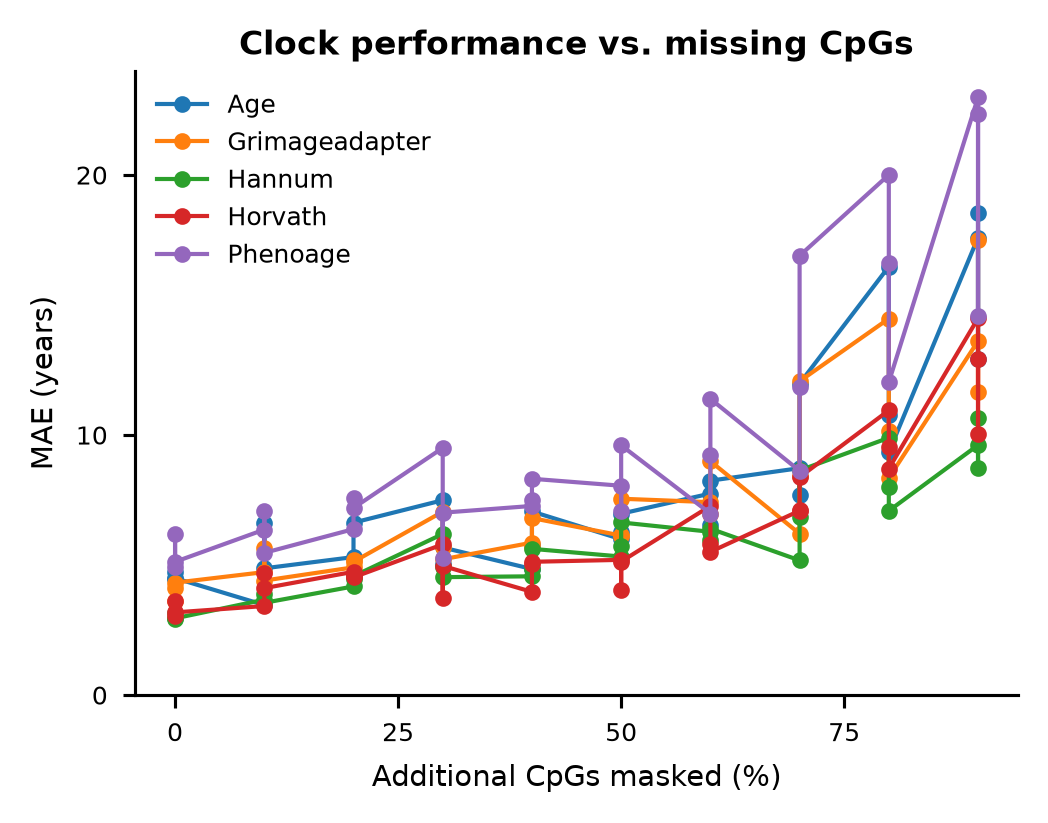

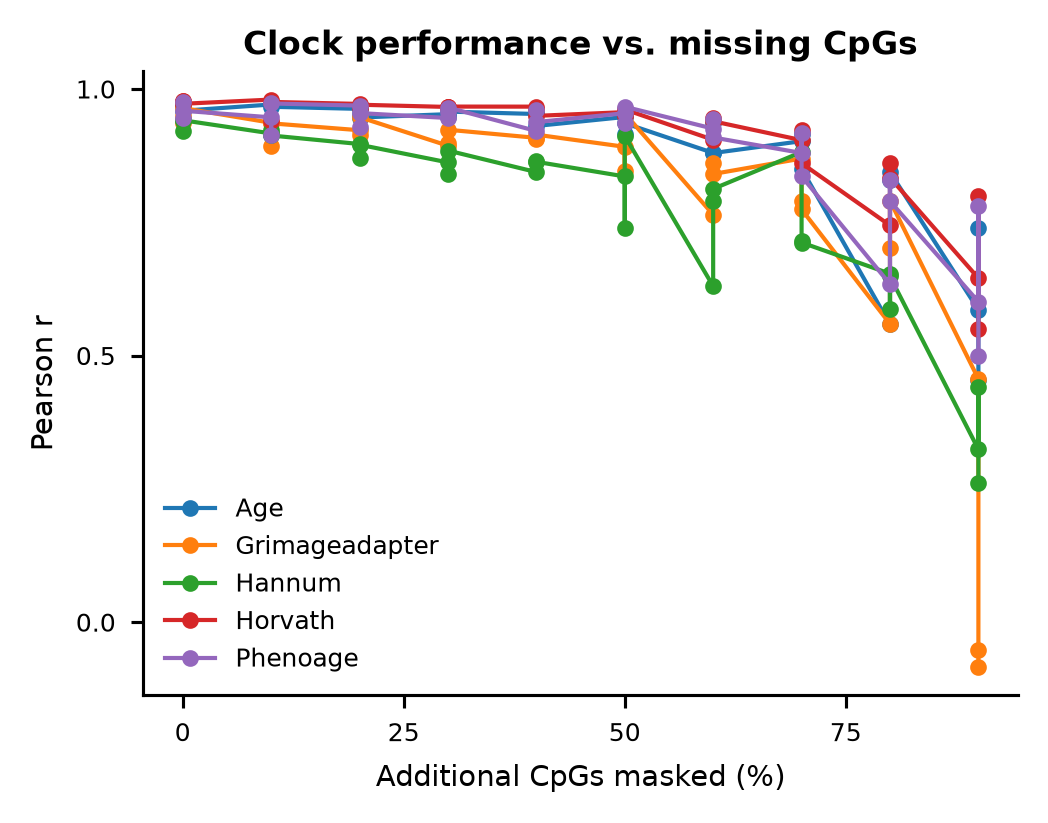

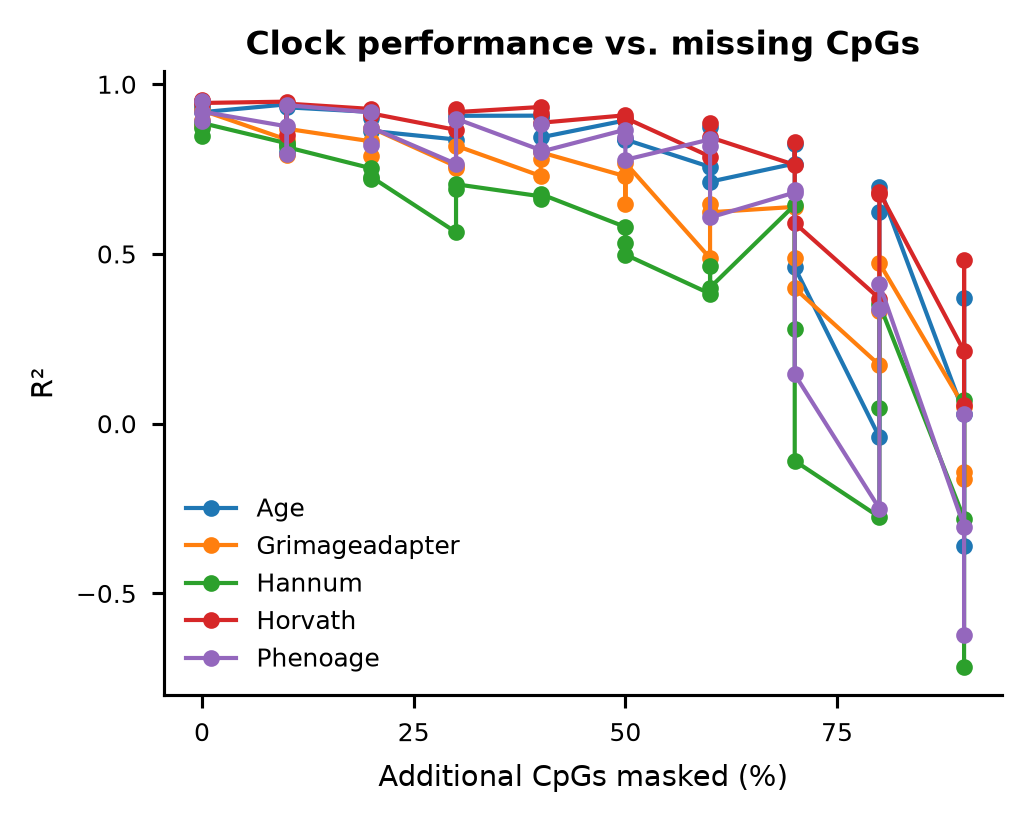

In [11]:
for metric in ("mae", "pearson_r", "r2"):
    fig, ax = eu.plot_missing_fraction_curves(mask_results, metric=metric,
                                               clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(Path(SAVE_DIR) / f"masking_curve_{metric}.pdf")
        fig.savefig(Path(SAVE_DIR) / f"masking_curve_{metric}.png")

## Analysis 2 — Real CpG coverage bins

Each sample's coverage is the fraction of vocab CpGs that are non-NaN in the aligned data. Samples are binned by this fraction and per-clock performance is computed within each bin, using only samples that have a true label for that clock.

In [12]:
coverage_dfs = []
for split in split_names:
    cov = eu.compute_sample_coverage(splits, clock_names, split=split)
    cov.insert(0, "split", split)
    coverage_dfs.append(cov)

coverage_df = pd.concat(coverage_dfs)

print("Coverage distribution:")
print(coverage_df["cpg_coverage"].describe().round(3))

Coverage distribution:
count    1743.000
mean        0.450
std         0.005
min         0.444
25%         0.444
50%         0.453
75%         0.453
max         0.453
Name: cpg_coverage, dtype: float64


In [13]:
coverage_results = eu.compute_coverage_performance(
    predictions, coverage_df, clock_names,
    n_bins      = N_COVERAGE_BINS,
    min_samples = MIN_BIN_SAMPLES,
)
display(coverage_results.round(3))

,clock,coverage_bin,coverage_mid,mae,pearson_r,r2,n
0,age,40%–60%,0.5,4.745,0.969,0.937,1743
1,grimageadapter_age,40%–60%,0.5,4.130,0.937,0.877,1743
2,hannum_age,40%–60%,0.5,3.158,0.921,0.847,1743
3,horvath_age,40%–60%,0.5,3.609,0.977,0.955,1743
4,phenoage_age,40%–60%,0.5,4.950,0.975,0.950,1743


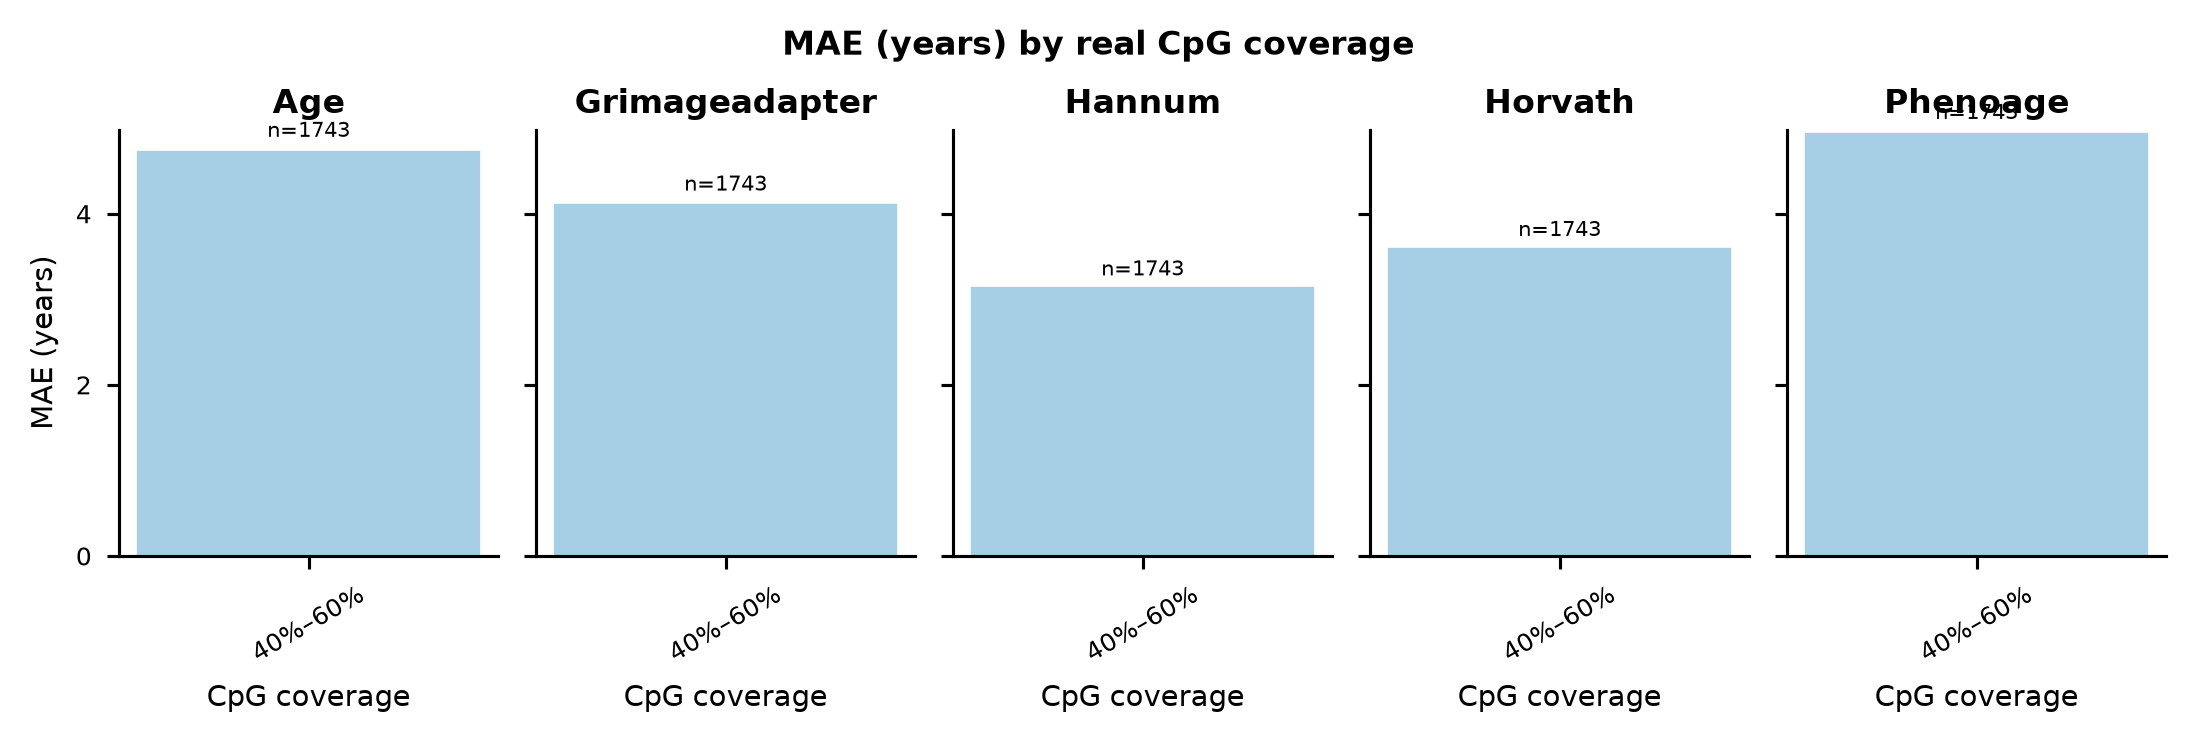

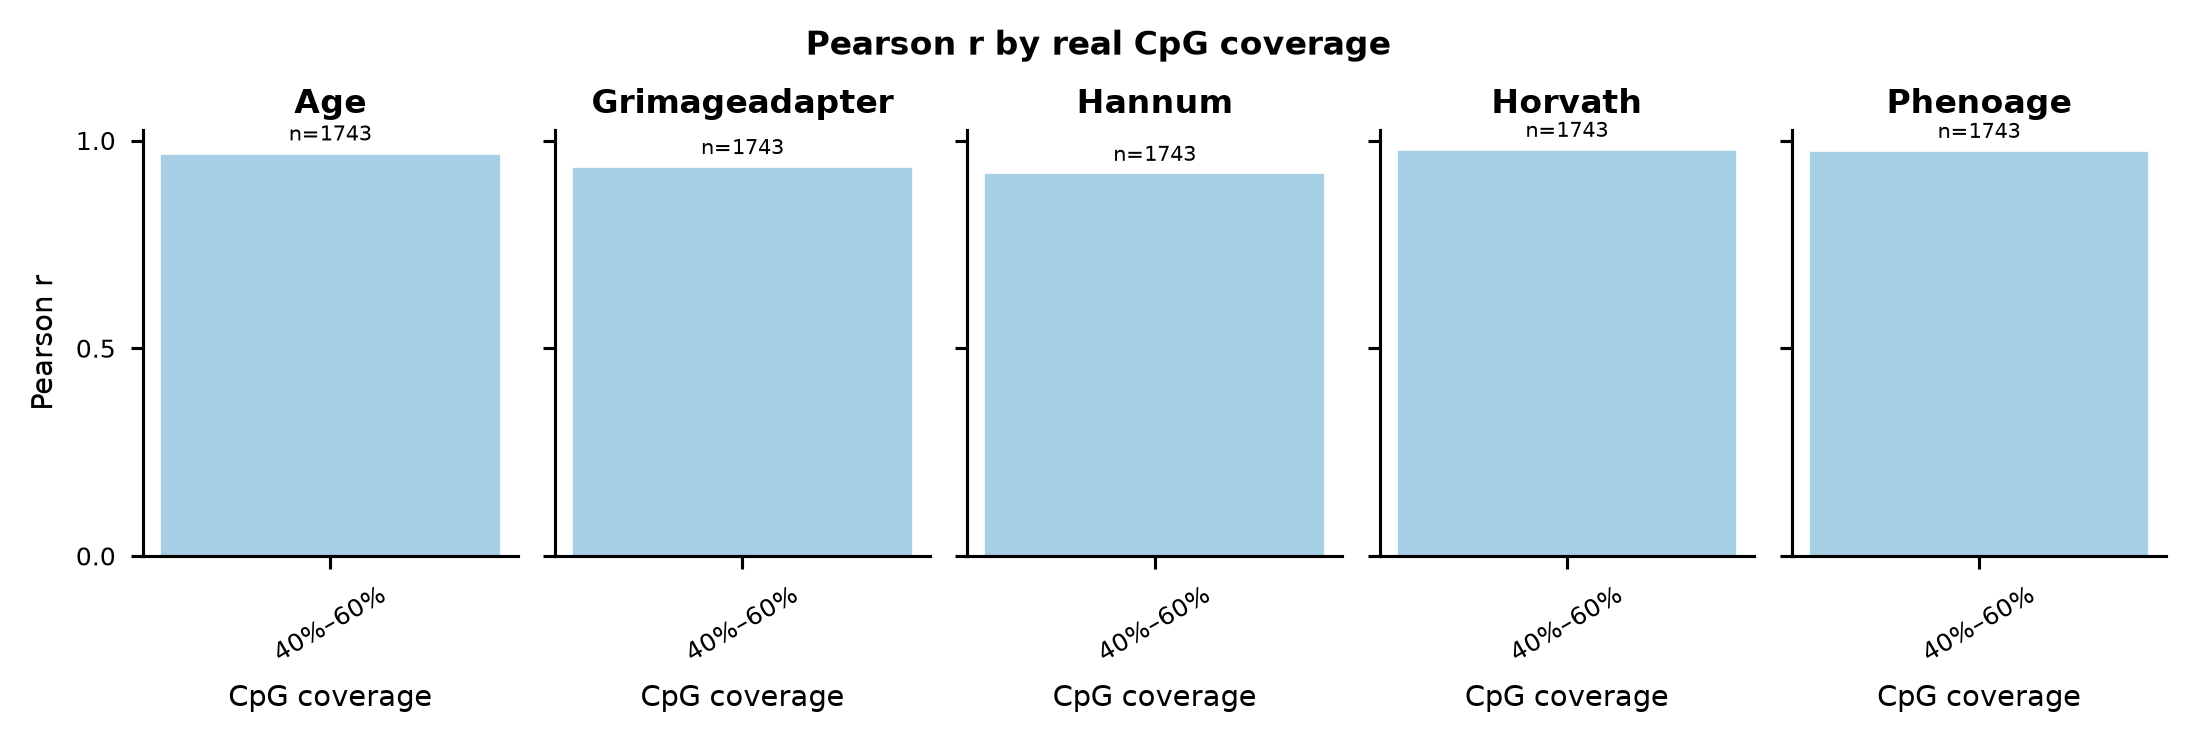

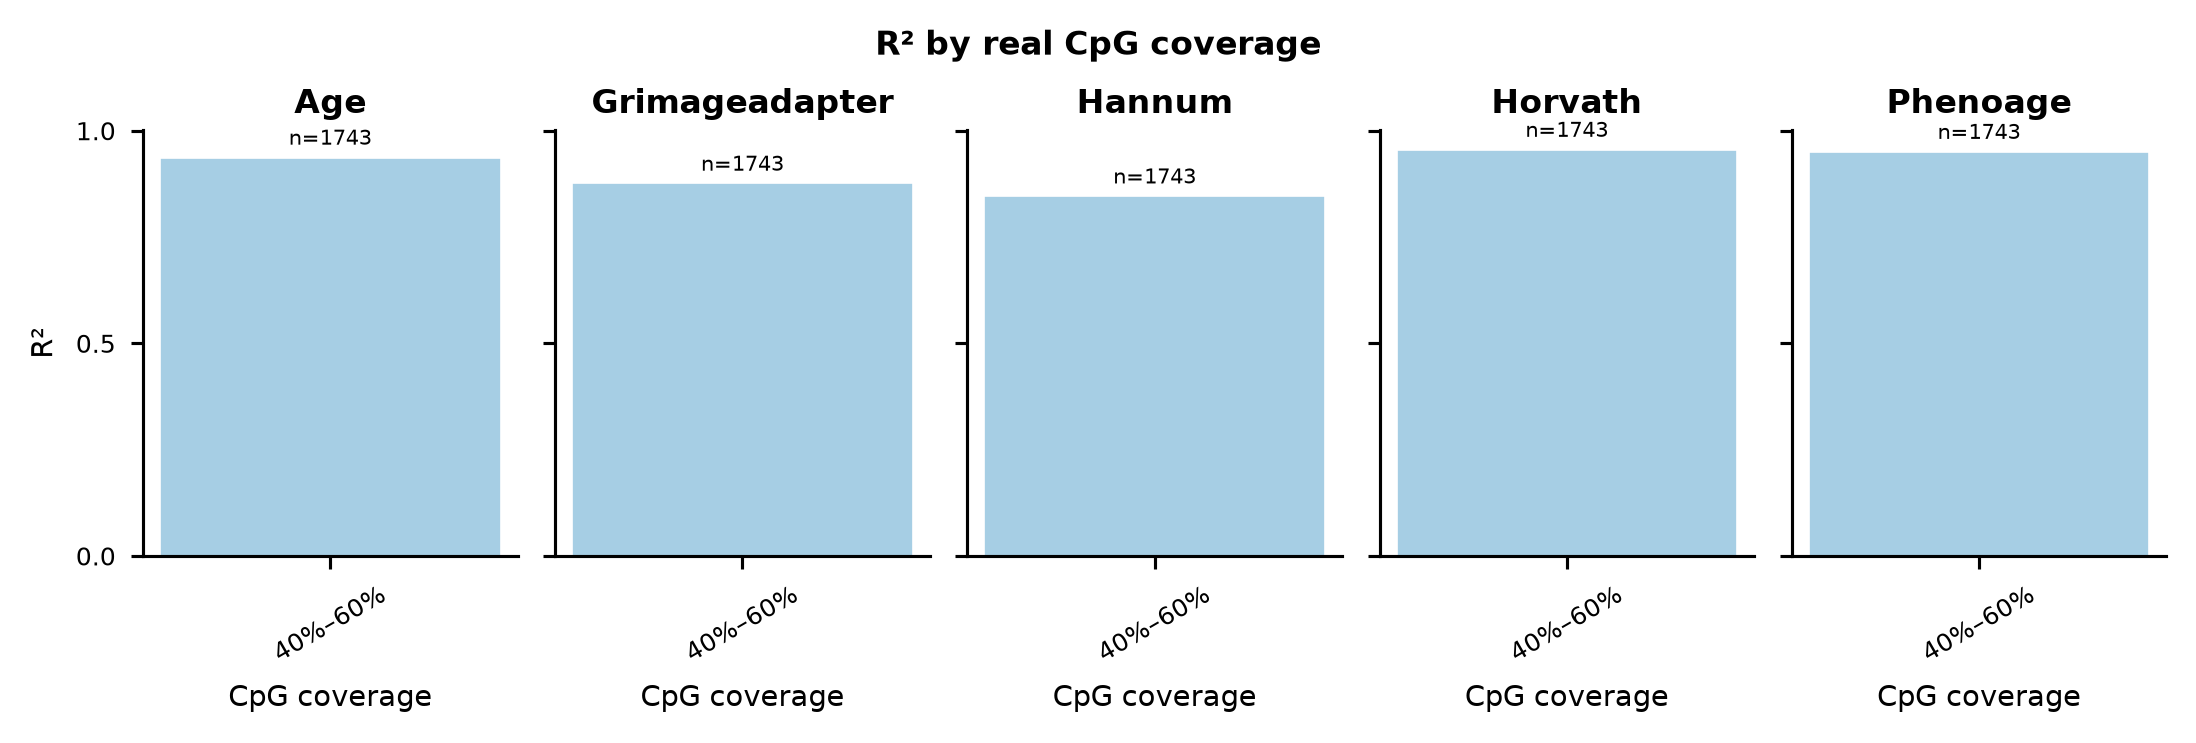

In [14]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_coverage_performance(coverage_results, metric=metric,
                                              clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(Path(SAVE_DIR) / f"coverage_bins_{metric}.pdf")
        fig.savefig(Path(SAVE_DIR) / f"coverage_bins_{metric}.png")
    plt.show()

## Summary: baseline vs. high missingness

Compare baseline (0 % extra masking) to the most heavily masked level, so the cost of missingness is immediately visible.

In [23]:
worst_frac = max(MASK_FRACTIONS)
worst      = mask_results[mask_results["mask_frac"] == worst_frac].set_index("clock")
worst      = worst[worst['split'] == 'train']

summary = baseline[["mae", "pearson_r", "r2"]].copy()
summary.columns = [f"baseline_{c}" for c in summary.columns]
for metric in ("mae", "pearson_r", "r2"):
    summary[f"masked_{metric}"] = worst[metric]
    delta = summary[f"masked_{metric}"] - summary[f"baseline_{metric}"]
    summary[f"delta_{metric}"] = delta.round(3)

display(summary.round(3))

,baseline_mae,baseline_pearson_r,baseline_r2,masked_mae,delta_mae,masked_pearson_r,delta_pearson_r,masked_r2,delta_r2
clock,,,,,,,,,
age,4.745,0.969,0.937,17.595,12.850,0.586,-0.383,0.029,-0.908
grimageadapter_age,4.130,0.937,0.877,13.614,9.484,0.456,-0.481,0.050,-0.827
hannum_age,3.158,0.921,0.847,9.615,6.457,0.324,-0.597,-0.280,-1.127
horvath_age,3.609,0.977,0.955,14.490,10.881,0.645,-0.332,0.213,-0.742
phenoage_age,4.950,0.975,0.950,22.989,18.039,0.601,-0.374,-0.303,-1.253
